In [1]:
!pip -q install catboost
!pip -q install xgboost
!pip -q install lightgbm

In [65]:
import pandas as pd
import numpy as np
from scipy import stats
from sklearn.metrics import mean_squared_error

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.compose import make_column_transformer, ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, StandardScaler, OneHotEncoder

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, VotingRegressor, StackingRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
import lightgbm as lgb
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.metrics import accuracy_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.tree import DecisionTreeClassifier

In [3]:
df_train = pd.read_csv('/content/train.csv')
df_test = pd.read_csv('/content/test.csv')

In [4]:
df_train.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [5]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [6]:
df_train.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


# **Outliers**

In [7]:
df_train.dtypes[df_train.dtypes != 'object']

,0
PassengerId,int64
Survived,int64
Pclass,int64
Age,float64
SibSp,int64
Parch,int64
Fare,float64


In [8]:
def view_outliers(df_train):
  outliers = {}
  num_cols = df_train.select_dtypes(include=['int64', 'float64']).columns

  for col in num_cols:
    Q1 = df_train[col].quantile(0.25)
    Q3 = df_train[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outlier_mask = (df_train[col] < lower_bound) | (df_train[col] > upper_bound)
    outliers[col] = outlier_mask.sum()


  return pd.Series(outliers).sort_values(ascending=False)


In [9]:
view_outliers(df_train)

,0
Parch,213
Fare,116
SibSp,46
Age,11
Pclass,0
PassengerId,0
Survived,0


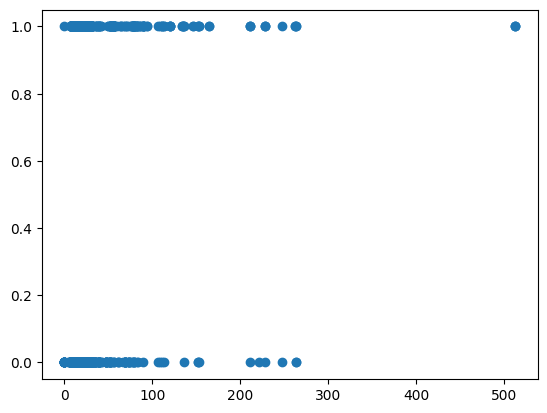

In [10]:
plt.scatter(x='Fare', y='Survived', data=df_train)

In [11]:
df_train.query('Fare > 300')
#259, 680, 738

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
258,259,1,1,"Ward, Miss. Anna",female,35.0,0,0,PC 17755,512.3292,NaN,C
679,680,1,1,"Cardeza, Mr. Thomas Drake Martinez",male,36.0,0,1,PC 17755,512.3292,B51 B53 B55,C
737,738,1,1,"Lesurer, Mr. Gustave J",male,35.0,0,0,PC 17755,512.3292,B101,C


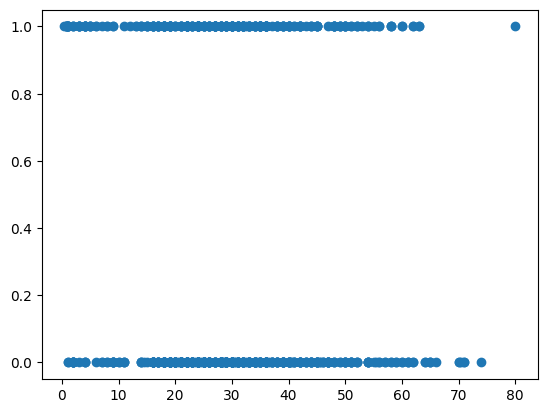

In [12]:
plt.scatter(x='Age', y='Survived', data=df_train)

In [13]:
df_train.query('Age > 80')

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked


In [14]:
val = [259, 680, 738]
df_train = df_train[df_train.PassengerId.isin(val) == False]

# **Valores Nulos**

In [15]:
pd.DataFrame(df_train.isnull().sum().sort_values(ascending=False)).head(28)

,0
Cabin,686
Age,177
Embarked,2
PassengerId,0
Name,0
Pclass,0
Survived,0
Sex,0
Parch,0
SibSp,0


In [16]:
df_train= df_train.drop(columns=['Cabin'])
df_test= df_test.drop(columns=['Cabin'])

# **Feature Engineering**

In [17]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 888 entries, 0 to 890
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  888 non-null    int64  
 1   Survived     888 non-null    int64  
 2   Pclass       888 non-null    int64  
 3   Name         888 non-null    object 
 4   Sex          888 non-null    object 
 5   Age          711 non-null    float64
 6   SibSp        888 non-null    int64  
 7   Parch        888 non-null    int64  
 8   Ticket       888 non-null    object 
 9   Fare         888 non-null    float64
 10  Embarked     886 non-null    object 
dtypes: float64(2), int64(5), object(4)
memory usage: 83.2+ KB


In [18]:
df_train.groupby(['Pclass'], as_index=False)['Survived'].mean()

,Pclass,Survived
0,1,0.624413
1,2,0.472826
2,3,0.242363


In [19]:
df_train.groupby(['Sex'], as_index=False)['Survived'].mean()

,Sex,Survived
0,female,0.741214
1,male,0.186087


In [20]:
df_train.groupby(['SibSp'], as_index=False)['Survived'].mean()

,SibSp,Survived
0,0,0.342149
1,1,0.535885
2,2,0.464286
3,3,0.250000
4,4,0.166667
5,5,0.000000
6,8,0.000000


In [21]:
df_train.groupby(['Embarked'], as_index=False)['Survived'].mean()

,Embarked,Survived
0,C,0.545455
1,Q,0.389610
2,S,0.336957


In [22]:
df_train['Sex_Pclass'] = df_train['Sex'] + '_' + df_train['Pclass'].astype(str)
df_test['Sex_Pclass'] = df_test['Sex'] + '_' + df_test['Pclass'].astype(str)

In [23]:
df_train['FamilySize'] = df_train['SibSp'] + df_train['Parch'] + 1
df_test['FamilySize'] = df_test['SibSp'] + df_test['Parch'] + 1

In [24]:
df_train.groupby(['FamilySize'], as_index=False)['Survived'].mean()

,FamilySize,Survived
0,1,0.300935
1,2,0.550000
2,3,0.578431
3,4,0.724138
4,5,0.200000
5,6,0.136364
6,7,0.333333
7,8,0.000000
8,11,0.000000


In [25]:
familly_map = {1: 'Alone', 2:'Small', 3:'Small', 4:'Small', 5:'Medium', 6:'Medium', 7:'Large', 8:'Large', 11:'Large'}
df_train['Familly_Size_Groups'] = df_train['FamilySize'].map(familly_map)
df_test['Familly_Size_Groups'] = df_test['FamilySize'].map(familly_map)

In [26]:
df_train.groupby(['Familly_Size_Groups'], as_index=False)['Survived'].mean()

,Familly_Size_Groups,Survived
0,Alone,0.300935
1,Large,0.160000
2,Medium,0.162162
3,Small,0.577320


In [27]:
df_train['Age_Group'] = pd.cut(df_train['Age'], 8)
df_test['Age_Group'] = pd.cut(df_test['Age'], 8)

In [28]:
df_train.groupby(['Age_Group'], as_index=False)['Survived'].mean()

<ipython-input-28-3355166979>:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_train.groupby(['Age_Group'], as_index=False)['Survived'].mean()


,Age_Group,Survived
0,"(0.34, 10.368]",0.593750
1,"(10.368, 20.315]",0.382609
2,"(20.315, 30.263]",0.365217
3,"(30.263, 40.21]",0.434211
4,"(40.21, 50.158]",0.383721
5,"(50.158, 60.105]",0.404762
6,"(60.105, 70.052]",0.235294
7,"(70.052, 80.0]",0.200000


In [29]:
df_train.loc[df_train['Age'] <= 19, 'Age'] = 0
df_train.loc[(df_train['Age'] > 19) & (df_train['Age'] <= 25), 'Age'] = 1
df_train.loc[(df_train['Age'] > 25) & (df_train['Age'] <= 31.8), 'Age'] = 2
df_train.loc[(df_train['Age'] > 31.8) & (df_train['Age'] <= 41), 'Age'] = 3
df_train.loc[(df_train['Age'] > 41) & (df_train['Age'] <= 80), 'Age'] = 4

df_test.loc[df_test['Age'] <= 19, 'Age'] = 0
df_test.loc[(df_test['Age'] > 19) & (df_test['Age'] <= 25), 'Age'] = 1
df_test.loc[(df_test['Age'] > 25) & (df_test['Age'] <= 31.8), 'Age'] = 2
df_test.loc[(df_test['Age'] > 31.8) & (df_test['Age'] <= 41), 'Age'] = 3
df_test.loc[(df_test['Age'] > 41) & (df_test['Age'] <= 80), 'Age'] = 4

In [30]:
df_train['Fare_Per_Person'] = df_train['Fare'] / df_train['FamilySize']
df_test['Fare_Per_Person'] = df_test['Fare'] / df_test['FamilySize']

In [31]:
df_train = df_train.drop(columns=['PassengerId','Name', 'FamilySize', 'Ticket'])
df_test = df_test.drop(columns=['PassengerId', 'Name', 'FamilySize', 'Ticket'])

<Axes: xlabel='Survived', ylabel='Count'>

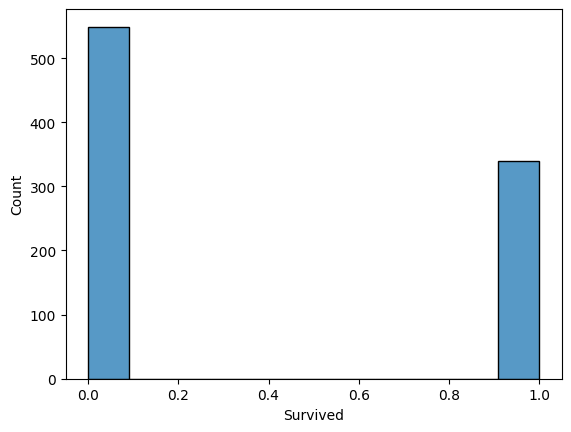

In [32]:
sns.histplot(df_train, x=df_train['Survived'])

# **Pipeline**

In [33]:
df_train.dtypes[df_train.dtypes == 'object']

,0
Sex,object
Embarked,object
Sex_Pclass,object
Familly_Size_Groups,object


In [34]:
df_train.dtypes[df_train.dtypes != 'object']

,0
Survived,int64
Pclass,int64
Age,float64
SibSp,int64
Parch,int64
Fare,float64
Age_Group,category
Fare_Per_Person,float64


In [35]:
onh_enc = ['Sex', 'Embarked', 'Sex_Pclass', 'Familly_Size_Groups', 'Age_Group']

In [36]:
class outlier(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.means_ = X.mean()
        self.Q1 = X.quantile(0.25)
        self.Q3 = X.quantile(0.75)
        self.IQR = self.Q3 - self.Q1
        return self

    def transform(self, X):
        X = X.copy()
        lower_bound = self.Q1 - 1.5 * self.IQR
        upper_bound = self.Q3 + 1.5 * self.IQR

        for col in X.columns:
            outliers = (X[col] < lower_bound[col]) | (X[col] > upper_bound[col])
            X.loc[outliers, col] = X[col].median()
        return X

In [37]:
num_cols = df_train.select_dtypes(include=['int64', 'float64']).columns
num_cols = num_cols.drop('Survived')

num_pipeline = Pipeline(steps=[
    ('outlier_handler', outlier()),
    ('imputer', SimpleImputer(strategy='mean'))
])


In [38]:
onh_pipeline = Pipeline(steps=[
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

In [39]:
col_trans = ColumnTransformer(transformers=[
    ('num_p', num_pipeline, num_cols),
    ('onh_p', onh_pipeline, onh_enc),
    ],
    remainder='passthrough',
    n_jobs=-1)

In [40]:
X = df_train.drop('Survived', axis=1)
y = df_train['Survived']

In [41]:
pipeline = Pipeline(steps=[
    ('preprocessing', col_trans)
])

In [42]:
X_preprocessed = pipeline.fit_transform(X)

In [43]:
X_train, X_test, y_train, y_test = train_test_split(X_preprocessed, y, test_size=0.2, random_state=25)

# **Treinamento**

Random Forest

In [50]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)

In [51]:
rf.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [52]:
y_pred_rf = rf.predict(X_test)

In [53]:
accuracy = accuracy_score(y_test, y_pred_rf)
print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.7528


Boost

In [59]:
xgb = XGBClassifier(n_estimators=500, learning_rate=0.05, max_depth=4, random_state=42)

In [61]:
xgb.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=4, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=500, n_jobs=None,
              num_parallel_tree=None, random_state=42, ...)

In [62]:
y_pred_xgb = xgb.predict(X_test)

In [64]:
accuracy = accuracy_score(y_test, y_pred_xgb)
print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.8090


Decision Tree

In [66]:
dt = DecisionTreeClassifier(random_state=42)

In [67]:
dt.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

In [68]:
y_pred_dt = dt.predict(X_test)

In [69]:
accuracy = accuracy_score(y_test, y_pred_dt)
print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.7640
